In [ ]:
import os
# import scipy
import numpy as np
import pandas as pd
# import torch
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm

from compcats.localizer import localizer

import main_analysis as ma
import paths

# Matplotlib settings
import matplotlib as mpl
from matplotlib import rcParams
rcParams.update({'figure.autolayout': False})
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
# Font
font_path = '/home/alishd/.fonts/Avenir.ttc'
avenir_font = fm.FontProperties(fname=font_path)
mpl.rcParams['font.family'] = avenir_font.get_name()
ttc = fm.get_font(font_path)
print("Font name from TTC:", ttc.family_name)
print("Style:", ttc.style_name)

RESULTS_DIR = 'results/exploration'
os.makedirs(RESULTS_DIR, exist_ok=True)
MODELS_DIR = 'models'
PLOTS_DIR = f'{RESULTS_DIR}/plots/postvss25'
os.makedirs(PLOTS_DIR, exist_ok=True)

NSD_DIR = paths.NSD_DIR
GRILLSPECTOR_LOCALIZER_DIR = paths.GRILLSPECTOR_LOCALIZER_DIR
KONKLE_LOCALIZER_DIR = paths.KONKLE_LOCALIZER_DIR
KANWISHER_LOCALIZER_DIR = paths.KANWISHER_LOCALIZER_DIR

Font name from TTC: Avenir
Style: Book


In [47]:
results_dict = {}

# % category-selective units vs. correlation

In [ ]:
ALL_MODELS = ma.get_all_models()

LOCALIZER_DIR = GRILLSPECTOR_LOCALIZER_DIR
LOCALIZER_NAME = 'grillspector'
TTHRESHOLD = 7
FROIS = ['FFA', 'PPA', 'EBA']

MODELSUBJECT_CORRELATIONS_CSV_PATH = f'{RESULTS_DIR}/modelsubject_correlations_nsd515.csv'
CORRELATIONS_DF = pd.read_csv(MODELSUBJECT_CORRELATIONS_CSV_PATH)

def get_model_percentage_froi_units(froi, model, layer):
    """
    Get the percentage of units in the model that are in the specified fROI.
    """
    froi_mask = localizer.get_froi_mask(
        LOCALIZER_DIR, LOCALIZER_NAME, MODELS_DIR,
        model, layer, froi, tthreshold=TTHRESHOLD
    )
    n_units_froi = froi_mask.sum()
    n_units_total = froi_mask.numel()
    percent_froi_units = n_units_froi / n_units_total * 100
    return percent_froi_units.item()

def get_model_brain_correlations(model_name, layer, froi, CORRELATIONS_DF):
    """
    Get the brain correlations for the model in the specified fROI.
    """
    correlations_df = CORRELATIONS_DF
    model_df = correlations_df[
        (correlations_df['model_name'] == model_name) &
        (correlations_df['model_layer'] == layer) &
        (correlations_df['model_froi'] == froi) &
        (correlations_df['model_tthreshold'] == TTHRESHOLD) &
        (correlations_df['model_localizer'] == LOCALIZER_NAME) &
        (correlations_df['fmri_froi'] == froi) &
        (correlations_df['fmri_tthreshold'] == TTHRESHOLD)
    ]
    normed_pearsonr = model_df['normed_pearsonr'].median()
    normed_rdmr = model_df['normed_rdmr'].median()
    return normed_pearsonr, normed_rdmr

Using cache found in /home/alishd/.cache/torch/hub/harvard-visionlab_open_ipcl_main


/home/alishd/.cache/torch/checkpoints/1a6IO4xhWy8cdyAuWv0BxSONz7lMcKbZE.pth.tar


/om2/user/alishd/anaconda/envs/catsel/lib/python3.12/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/om2/user/alishd/anaconda/envs/catsel/lib/python3.12/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Using cached ./models


No pretrained configuration specified for vit_base_patch16_224_in21k model. Using a default. Please add a config to the model pretrained_cfg registry or pass explicitly.
Using cache found in /home/alishd/.cache/torch/hub/facebookresearch_dinov2_main
/home/alishd/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:43: UserWarning: xFormers is available (SwiGLU)
  warnings.warn("xFormers is available (SwiGLU)")
/home/alishd/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:27: UserWarning: xFormers is available (Attention)
  warnings.warn("xFormers is available (Attention)")
/home/alishd/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:33: UserWarning: xFormers is available (Block)
  warnings.warn("xFormers is available (Block)")
Using cache found in /home/alishd/.cache/torch/hub/facebookresearch_dinov2_main


In [48]:
for froi in FROIS:
    if froi not in results_dict:
        results_dict[froi] = []
    for model_name, model in ALL_MODELS.items():
        model_results = {}
        layer = ma.get_froi_models_layers(froi, froi)[model_name]
        percent_froi_units = get_model_percentage_froi_units(froi, model, layer)
        normed_pearsonr, normed_rdmr = get_model_brain_correlations(
            model_name, layer, froi, CORRELATIONS_DF
        )
        model_results.update({
            'model_name': model_name,
            'model_layer': layer,
            'froi': froi,
            'tthreshold': TTHRESHOLD,
            'localizer': LOCALIZER_NAME,
            'percent_froi_units': percent_froi_units,
            'normed_pearsonr_median': normed_pearsonr,
            'normed_rdmr_median': normed_rdmr
        })
        results_dict[froi].append(model_results)

In [49]:
results_dir = f'{RESULTS_DIR}/similarity_causes'
os.makedirs(results_dir, exist_ok=True)
for froi in FROIS:
    results_df = pd.DataFrame(results_dict[froi])
    results_df.to_csv(f'{results_dir}/similarity_causes_{froi}.csv', index=False)
    print(f"Results for {froi} saved to {results_dir}/similarity_causes_{froi}.csv")

Results for FFA saved to results/exploration/similarity_causes/similarity_causes_FFA.csv
Results for PPA saved to results/exploration/similarity_causes/similarity_causes_PPA.csv
Results for EBA saved to results/exploration/similarity_causes/similarity_causes_EBA.csv


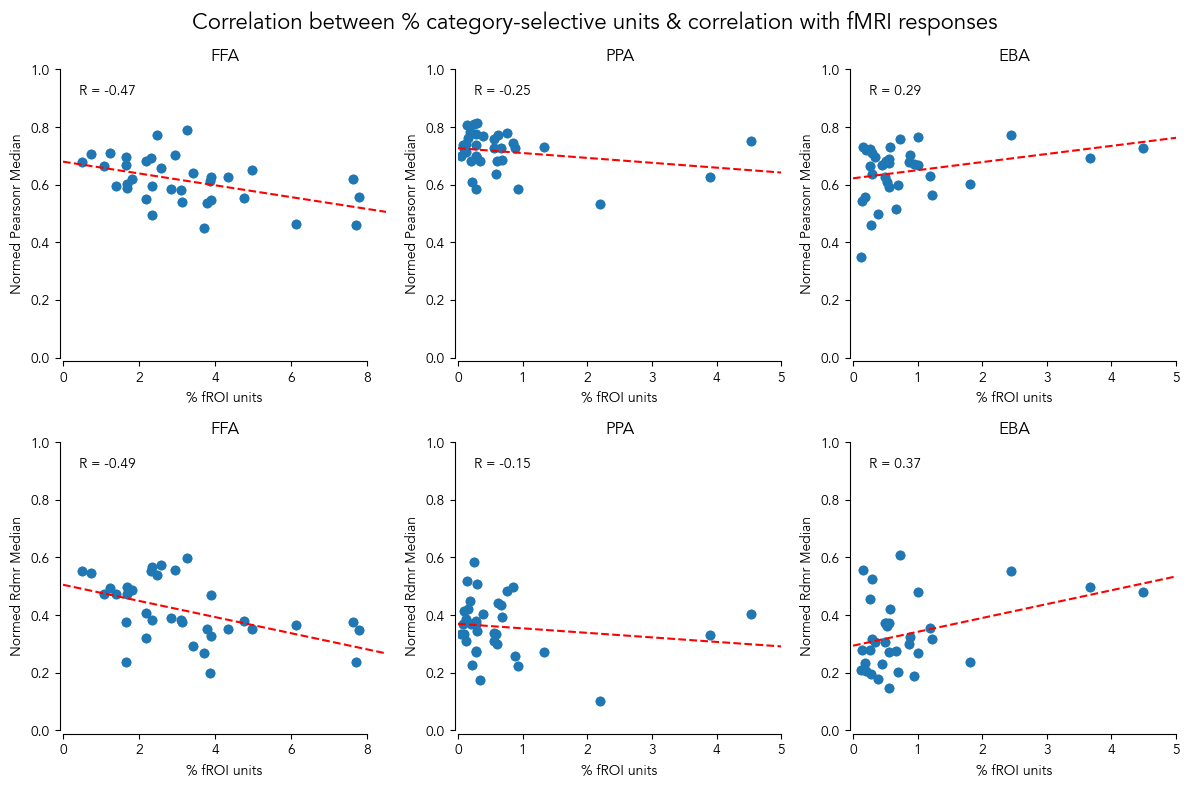

In [39]:
savefig = False

# Make a 2 x 3 figure with metric (normed_pearsonr_median and normed_rdmr_median) as rows and frois as columns
fig, axs = plt.subplots(2, 3, figsize=(12, 8),
                        gridspec_kw={'width_ratios': [1, 1, 1], 'height_ratios': [1, 1]})
fig.suptitle('Correlation between % category-selective units & correlation with fMRI responses', fontsize=16, fontproperties=avenir_font)

froi_lims = {
    'FFA': {
        'plot_lim': (0, 8.5),
        'x_axis_lim': (0, 8),
    },
    'PPA': {
        'plot_lim': (0, 5),
        'x_axis_lim': (0, 5),
    },
    'EBA': {
        'plot_lim': (0, 5),
        'x_axis_lim': (0, 5),
    }
}

# For each subplot, plot the % froi units vs. the metric for each model
for i, froi in enumerate(FROIS):
    for j, metric in enumerate(['normed_pearsonr_median', 'normed_rdmr_median']):
        ax = axs[j, i]
        ax.set_title(froi)
        ax.set_xlabel('% fROI units')
        ax.set_ylabel(metric.replace('_', ' ').title())
        
        # Extract data for the current froi
        froi_data = results_dict[froi]
        percent_froi_units = [d['percent_froi_units'] for d in froi_data]
        metric_values = [d[metric] for d in froi_data]

        # Plot the regression line and write the correlation coefficient
        if len(percent_froi_units) > 1 and len(metric_values) > 1:
            # Fit a linear regression model
            coeffs = np.polyfit(percent_froi_units, metric_values, 1)
            # Generate x values for the regression line
            x_fit = np.linspace(0, 10, 100)
            # Calculate the corresponding y values
            y_fit = np.polyval(coeffs, x_fit)
            # Plot the regression line
            ax.plot(x_fit, y_fit, color='red', linestyle='--', linewidth=1.5)
            # Calculate the correlation coefficient
            correlation_coefficient = np.corrcoef(percent_froi_units, metric_values)[0, 1]
            # Write the correlation coefficient on the plot
            ax.text(0.05, 0.95, f'R = {correlation_coefficient:.2f}',
                    transform=ax.transAxes, fontsize=10, verticalalignment='top',
                    bbox=dict(facecolor='white', alpha=0.5, edgecolor='none'))
        
        # Plot the data
        ax.scatter(percent_froi_units, metric_values, label=froi)
        ax.set_xlim(froi_lims[froi]['plot_lim'])
        ax.set_ylim(0, 1)
        # ax.set_xticks(np.arange(0, 101, 20))
        ax.set_yticks(np.arange(0, 1.1, 0.2))
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_position(('outward', 2.5))
        ax.spines['bottom'].set_position(('outward', 2.5))
        ax.spines['bottom'].set_bounds(0, froi_lims[froi]['x_axis_lim'][1])
        ax.tick_params(axis='both', which='major', labelsize=10)
# Adjust layout
# plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.tight_layout()
# Save the figure
plot_dir = PLOTS_DIR
os.makedirs(plot_dir, exist_ok=True)
if savefig:  # Change to `savefig` variable if needed
    raise NotImplementedError("Saving figures is not implemented in this code snippet.")
    # plt.savefig(f'{plot_dir}/model_performance_by_froi.pdf', dpi=300, bbox_inches='tight', transparent=True)
else:
    plt.show()
plt.close()